In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

import openTSNE
import pandas as pd
import numpy as np
import pickle


import torch
from sklearn.decomposition import PCA
from datasets import load_dataset, load_from_disk

## Load precomputed models encoddings

In [2]:
def load_model_encodings(filepath):
    with open(filepath, "rb") as f:
        encoding_dict = pickle.load(f)
    return encoding_dict

In [3]:
blosum_concat_mlp_dict = load_model_encodings("../data/encodings/blosum_concat_test50540_MLPnotrain.pkl")
esm2_concat_mlp_dict = load_model_encodings("../data/encodings/esm2_concat_test50540_MLPnotrain.pkl")
blosum_concat_cnn_dict2 = load_model_encodings("../data/encodings/blosum_concat_test50540_CNNnotrain.pkl")
esm2_concat_cnn_dict2 = load_model_encodings("../data/encodings/esm2_concat_test50540_CNNnotrain.pkl")


blosum_concat_mlp_dict3 = load_model_encodings("../data/encodings/blosum_concat_test50540_MLPtrained.pkl")
esm2_concat_mlp_dict3 = load_model_encodings("../data/encodings/esm2_concat_test50540_MLPtrained.pkl")
blosum_concat_cnn_dict4 = load_model_encodings("../data/encodings/blosum_concat_test50540_CNNtrained.pkl")
esm2_concat_cnn_dict4 = load_model_encodings("../data/encodings/esm2_concat_test50540_CNNtrained.pkl")


In [4]:
blosum_labels = blosum_concat_mlp_dict["labels"]
blosum_labels = np.where(blosum_labels == 1,"cleavage site","non-cleavage site")

esm2_labels = esm2_concat_mlp_dict["labels"]
esm2_labels = np.where(esm2_labels == 1,"cleavage site","non-cleavage site")


# blosum_labels2 = blosum_concat_mlp_dict2["labels"]
# blosum_labels2 = np.where(blosum_labels2 == 1,"cleavage site","non-cleavage site")


In [6]:
### BLOSUM62 concat encoding MLP model non-trained


aff_mult_blosum62 = openTSNE.affinity.Multiscale(
    blosum_concat_mlp_dict["encoding"],
    perplexities=[50, 500],
    metric="cosine",
    n_jobs=12,
    random_state=42,
    verbose=True
)

initBlosum62 = openTSNE.initialization.pca(blosum_concat_mlp_dict["encoding"], random_state=42)

blosum62_tsne_multi = openTSNE.TSNE(n_jobs=12).fit(
    affinities=aff_mult_blosum62,
    initialization=initBlosum62,
)

===> Finding 1500 nearest neighbors using Annoy approximate search using cosine distance...
   --> Time elapsed: 32.69 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 11.67 seconds


In [10]:
### BLOSUM62 concat encoding MLP model trained


aff_mult_blosum62_t = openTSNE.affinity.Multiscale(
    blosum_concat_mlp_dict3["encoding"],
    perplexities=[50, 500],
    metric="cosine",
    n_jobs=12,
    random_state=42,
    verbose=True
)

initBlosum62_t = openTSNE.initialization.pca(blosum_concat_mlp_dict3["encoding"], random_state=42)

blosum62_tsne_multi_t = openTSNE.TSNE(n_jobs=12).fit(
    affinities=aff_mult_blosum62_t,
    initialization=initBlosum62_t,
)

===> Finding 1500 nearest neighbors using Annoy approximate search using cosine distance...
   --> Time elapsed: 33.11 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 12.13 seconds


In [14]:
### ESM-2 concat encoding MLP model no trained


aff_mult_esm2 = openTSNE.affinity.Multiscale(
    esm2_concat_mlp_dict["encoding"],
    perplexities=[50, 500],
    metric="cosine",
    n_jobs=12,
    random_state=42,
    verbose=True
)

initEsm2 = openTSNE.initialization.pca(esm2_concat_mlp_dict["encoding"], random_state=42)

esm2_tsne_multi = openTSNE.TSNE(n_jobs=12).fit(
    affinities=aff_mult_esm2,
    initialization=initEsm2,
)

===> Finding 1500 nearest neighbors using Annoy approximate search using cosine distance...
   --> Time elapsed: 36.07 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 20.70 seconds


In [17]:
### ESM-2 concat encoding MLP model TRAINED


aff_mult_esm2_t = openTSNE.affinity.Multiscale(
    esm2_concat_mlp_dict3["encoding"],
    perplexities=[50, 500],
    metric="cosine",
    n_jobs=12,
    random_state=42,
    verbose=True
)

initEsm2_t = openTSNE.initialization.pca(esm2_concat_mlp_dict3["encoding"], random_state=42)

esm2_tsne_multi_t = openTSNE.TSNE(n_jobs=12).fit(
    affinities=aff_mult_esm2_t,
    initialization=initEsm2_t,
)

===> Finding 1500 nearest neighbors using Annoy approximate search using cosine distance...
   --> Time elapsed: 33.35 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 11.77 seconds


#### CNN models

In [33]:
blosum_concat_cnn_enc2 = blosum_concat_cnn_dict2["encoding"].reshape(50540,-1)

In [35]:
### BLOSUM62 concat encoding CNN model non-trained


aff_mult_blosum62_cnn = openTSNE.affinity.Multiscale(
    blosum_concat_cnn_enc2,
    perplexities=[50, 500],
    metric="cosine",
    n_jobs=12,
    random_state=42,
    verbose=True
)

initBlosum62_cnn = openTSNE.initialization.pca(blosum_concat_cnn_enc2, random_state=42)

blosum62_tsne_multi_cnn = openTSNE.TSNE(n_jobs=12).fit(
    affinities=aff_mult_blosum62_cnn,
    initialization=initBlosum62_cnn,
)

===> Finding 1500 nearest neighbors using Annoy approximate search using cosine distance...
   --> Time elapsed: 69.87 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 11.69 seconds


In [6]:
blosum_concat_cnn_enc4 = blosum_concat_cnn_dict4["encoding"].reshape(50540,-1)

In [7]:
### BLOSUM62 concat encoding CNN model TRAINED


aff_mult_blosum62_cnn4 = openTSNE.affinity.Multiscale(
    blosum_concat_cnn_enc4,
    perplexities=[50, 500],
    metric="cosine",
    n_jobs=12,
    random_state=42,
    verbose=True
)

initBlosum62_cnn4 = openTSNE.initialization.pca(blosum_concat_cnn_enc4, random_state=42)

blosum62_tsne_multi_cnn4 = openTSNE.TSNE(n_jobs=12).fit(
    affinities=aff_mult_blosum62_cnn4,
    initialization=initBlosum62_cnn4,
)

===> Finding 1500 nearest neighbors using Annoy approximate search using cosine distance...
   --> Time elapsed: 36.48 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 10.90 seconds


In [12]:
esm2_concat_cnn_enc4 = esm2_concat_cnn_dict4["encoding"].reshape(50540,-1)

In [15]:
aff_mult_esm2_cnn4 = openTSNE.affinity.Multiscale(
    esm2_concat_cnn_enc4,
    perplexities=[50, 500],
    metric="cosine",
    n_jobs=12,
    random_state=42,
    verbose=True
)

initEsm2_cnn4 = openTSNE.initialization.pca(esm2_concat_cnn_enc4, random_state=42)

esm2_tsne_multi_cnn4 = openTSNE.TSNE(n_jobs=12).fit(
    affinities=aff_mult_esm2_cnn4,
    initialization=initEsm2_cnn4,
)

===> Finding 1500 nearest neighbors using Annoy approximate search using cosine distance...
   --> Time elapsed: 34.44 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 11.13 seconds


## Plot t-SNE embeddings

In [8]:
def tsne_plot(data, labels, title="t-SNE Visualization of Sequence Embeddings",desc=None):
    # Create a DataFrame for plotting
    df_plot = pd.DataFrame({
        "x": data[:, 0],
        "y": data[:, 1],
        "sequence": labels  
    })
    
    # Create the T-SNE plot using Seaborn
    plt.figure(figsize=(10, 8))
    plt.axis('off')
    g = sns.scatterplot(data=df_plot, x="x", y="y", hue="sequence", palette=["blue", "orange"],alpha=0.3,s=15)  # Customize colors
    g.get_legend().set_title("")
    #g.legend(prop={'size': 20})
    plt.suptitle(title,fontsize=14,fontweight="bold",x=0.126,y=0.96,ha="left")
    plt.title(desc,fontsize=12,pad=10,loc="left")
    #plt.show()

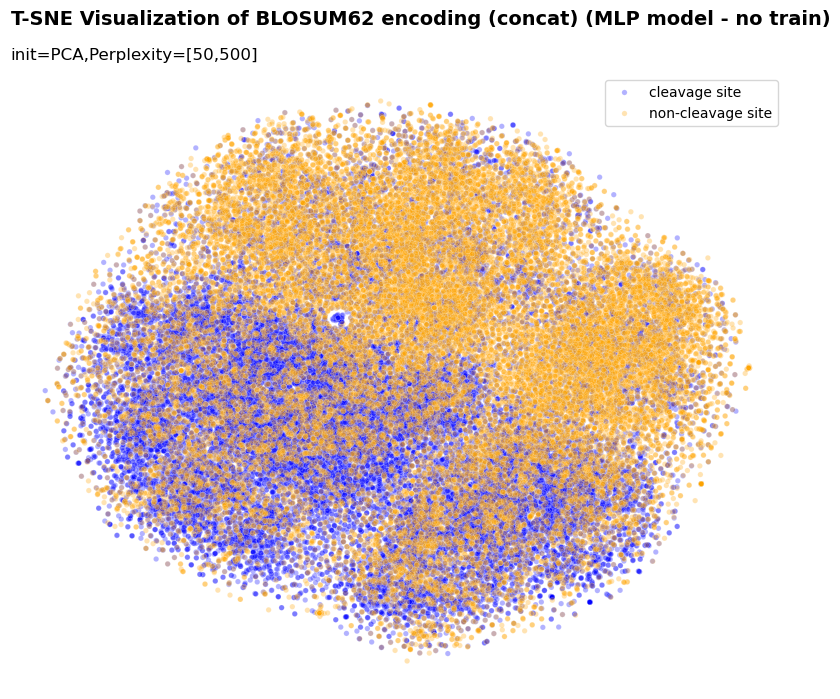

In [9]:
tsne_plot(blosum62_tsne_multi,blosum_labels,title="T-SNE Visualization of BLOSUM62 encoding (concat) (MLP model - no train)",desc="init=PCA,Perplexity=[50,500]")
plt.savefig(f'../outputs/blosum62concat_tsne_MLPnotrain.png',format='png',bbox_inches='tight',dpi=300)

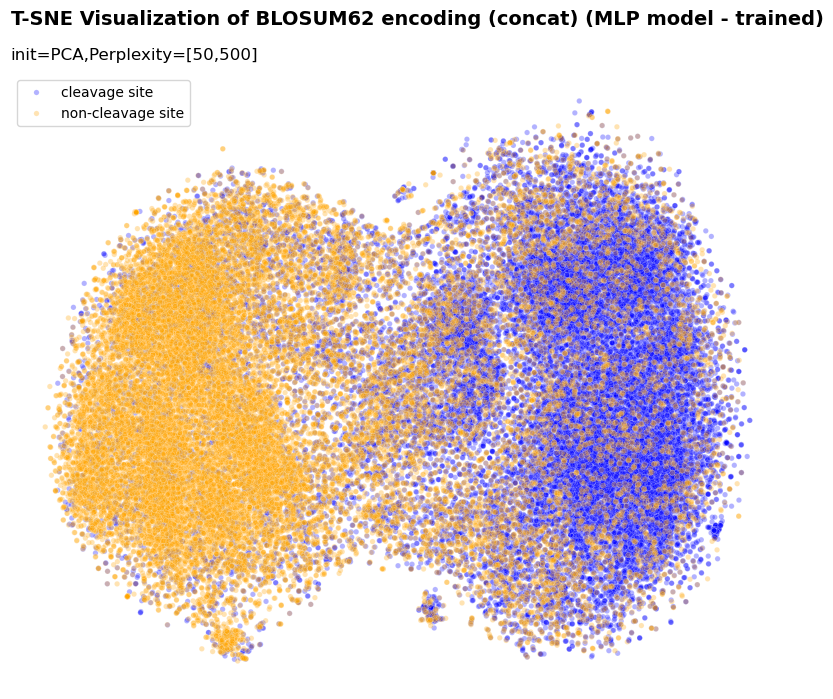

In [13]:
tsne_plot(blosum62_tsne_multi_t,blosum_labels,title="T-SNE Visualization of BLOSUM62 encoding (concat) (MLP model - trained)",desc="init=PCA,Perplexity=[50,500]")
plt.savefig(f'../outputs/blosum62concat_tsne_MLPtrain.png',format='png',bbox_inches='tight',dpi=300)

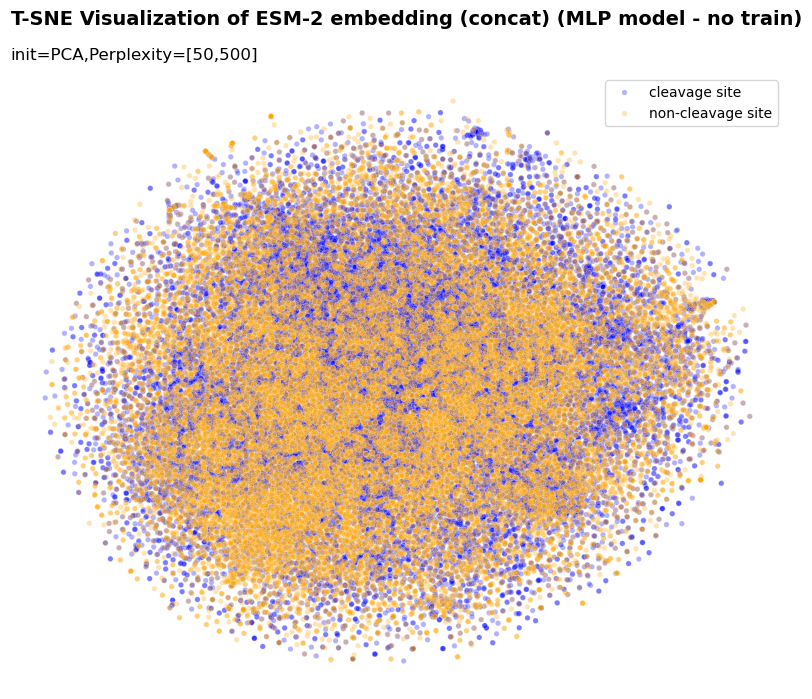

In [16]:
tsne_plot(esm2_tsne_multi,esm2_labels,title="T-SNE Visualization of ESM-2 embedding (concat) (MLP model - no train)",desc="init=PCA,Perplexity=[50,500]")
plt.savefig(f'../outputs/ESM2concat_tsne_MLPnotrain.png',format='png',bbox_inches='tight',dpi=300)

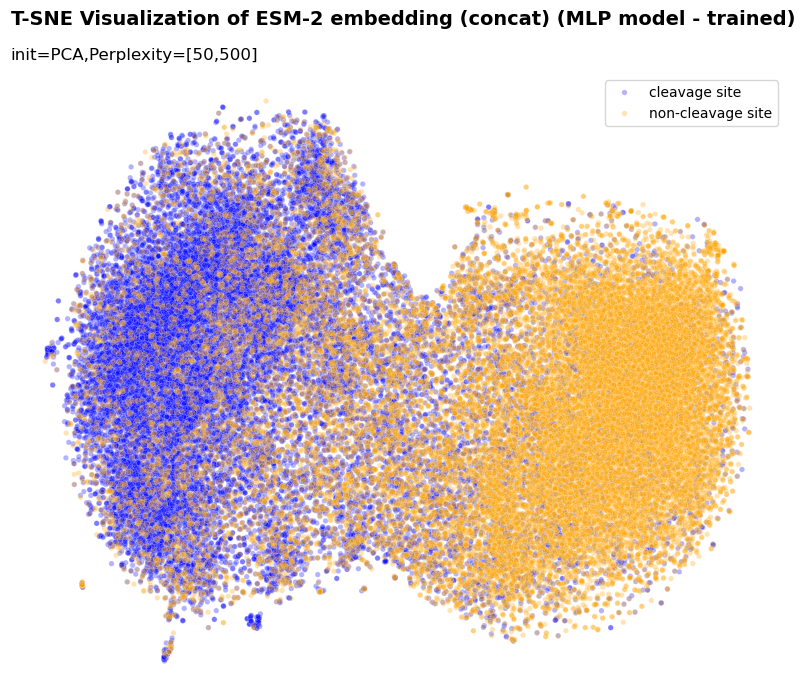

In [19]:
tsne_plot(esm2_tsne_multi_t,esm2_labels,title="T-SNE Visualization of ESM-2 embedding (concat) (MLP model - trained)",desc="init=PCA,Perplexity=[50,500]")
plt.savefig(f'../outputs/ESM2concat_tsne_MLPtrain.png',format='png',bbox_inches='tight',dpi=300)

## CNN models

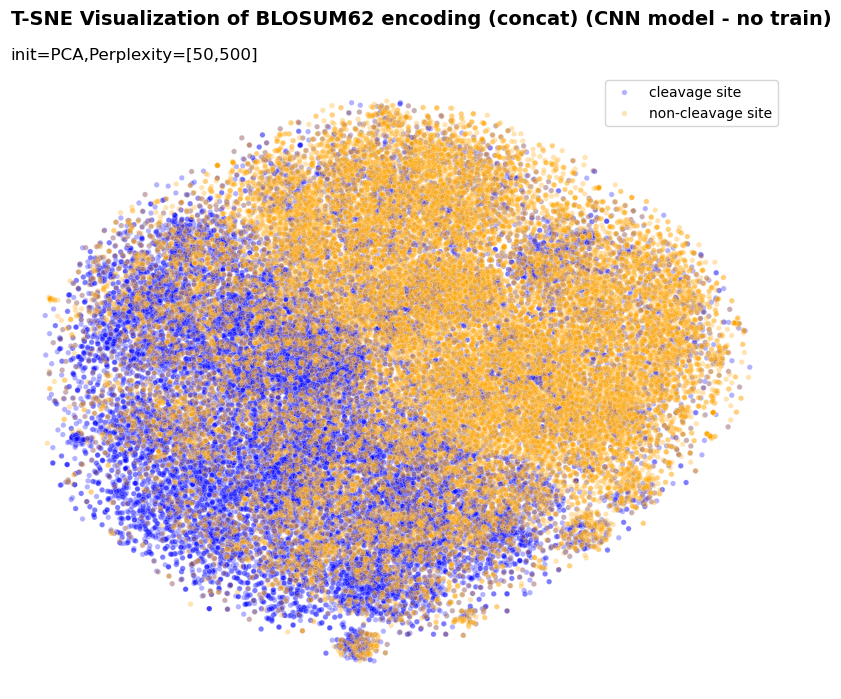

In [36]:
tsne_plot(blosum62_tsne_multi_cnn,blosum_labels,title="T-SNE Visualization of BLOSUM62 encoding (concat) (CNN model - no train)",desc="init=PCA,Perplexity=[50,500]")
plt.savefig(f'../outputs/blosum62concat_tsne_CNNnotrain.png',format='png',bbox_inches='tight',dpi=300)

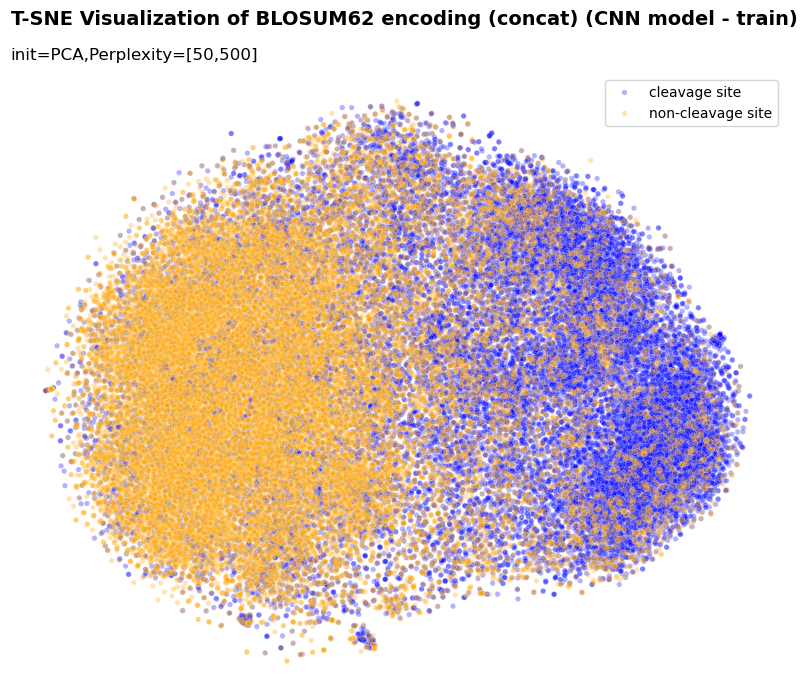

In [10]:
tsne_plot(blosum62_tsne_multi_cnn4,blosum_labels,title="T-SNE Visualization of BLOSUM62 encoding (concat) (CNN model - train)",desc="init=PCA,Perplexity=[50,500]")
plt.savefig(f'../outputs/blosum62concat_tsne_CNNtrain.png',format='png',bbox_inches='tight',dpi=300)

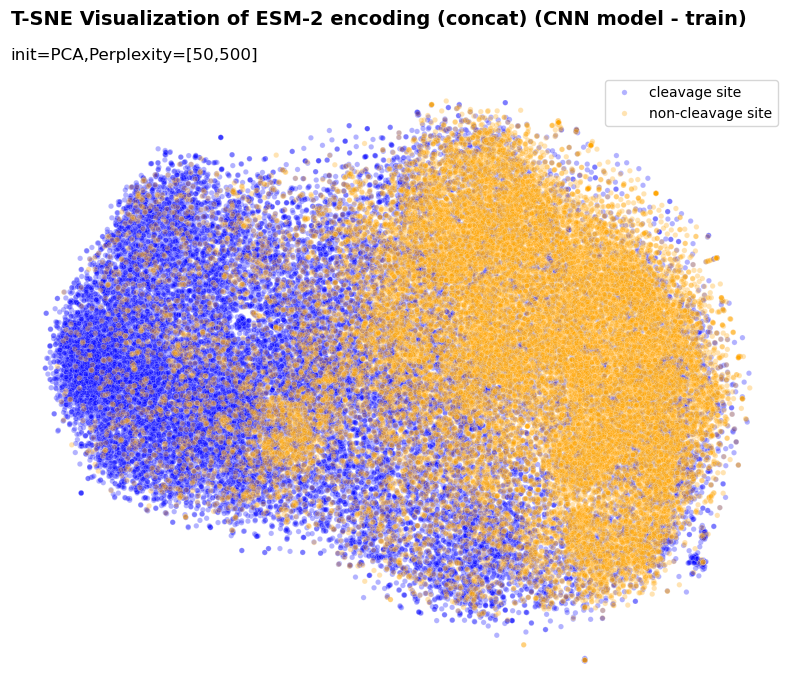

In [16]:
tsne_plot(esm2_tsne_multi_cnn4,esm2_labels,title="T-SNE Visualization of ESM-2 encoding (concat) (CNN model - train)",desc="init=PCA,Perplexity=[50,500]")
plt.savefig(f'../outputs/ESM2concat_tsne_CNNtrain.png',format='png',bbox_inches='tight',dpi=300)